In [19]:

import os
import sys
import json
import time
import warnings

from pathlib import Path

warnings.filterwarnings("ignore")

# Always start at Colab's root directory.
%cd /content

REPO_DIR = "/content/India-Demand-Forecasting-ML-day4"
BRANCH = "feature/features-and-models"

REPO_URL = (
    "https://github.com/tanishmaity03/"
    "India-Demand-Forecasting-ML.git"
)

# Clone the correct branch into a fresh, fixed directory.
if not os.path.isdir(os.path.join(REPO_DIR, ".git")):
    !git clone --single-branch --branch {BRANCH} {REPO_URL} {REPO_DIR}

# Enter the repository.
%cd /content/India-Demand-Forecasting-ML-day4

# Install the dependency required by src/features.py.
!pip install -q holidays

# Give Python priority access to this repository.
if REPO_DIR not in sys.path:
    sys.path.insert(0, REPO_DIR)

# Verify the repository and required files.
print("Current directory:", os.getcwd())

assert Path("src/features.py").is_file(), "src/features.py is missing."
assert Path("src/evaluate.py").is_file(), "src/evaluate.py is missing."
assert Path("data/processed/india_demand_weather.csv").is_file(), (
    "Processed dataset is missing."
)

# Verify imports before executing the rest of the notebook.
from src.features import build_features
from src.evaluate import split_mask, metrics

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import (
    RandomForestRegressor,
    HistGradientBoostingRegressor
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import (
    TimeSeriesSplit,
    RandomizedSearchCV
)

sns.set_theme(style="whitegrid")

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", None)

for folder in ["results/figures", "results/tables"]:
    Path(folder).mkdir(parents=True, exist_ok=True)

df = pd.read_csv(
    "data/processed/india_demand_weather.csv",
    parse_dates=["datetime"]
)

print("Git branch:", BRANCH)
print("Dataset shape:", df.shape)
print("Feature and evaluation modules imported successfully.")


/content
/content/India-Demand-Forecasting-ML-day4
Current directory: /content/India-Demand-Forecasting-ML-day4
Git branch: feature/features-and-models
Dataset shape: (46728, 20)
Feature and evaluation modules imported successfully.


In [20]:

N_ITER_HGB = 15
N_ITER_RF = 4
CV_SPLITS = 4

HGB_GRID = {
    "learning_rate": [0.03, 0.05, 0.08, 0.12],
    "max_iter": [200, 400, 600],
    "max_leaf_nodes": [15, 31, 63],
    "min_samples_leaf": [20, 50, 100],
    "l2_regularization": [0.0, 0.1, 1.0],
    "max_depth": [None, 6, 10]
}

RF_GRID = {
    "n_estimators": [100, 150],
    "min_samples_leaf": [3, 5, 10, 20],
    "max_features": [0.3, 0.5, 0.7],
    "max_depth": [None, 20, 30]
}


def tune(model, grid, n_iter, X, y, name):

    # Expanding-window time-series cross-validation.
    # Keep a 24-hour gap between training and validation folds.
    cv = TimeSeriesSplit(
        n_splits=CV_SPLITS,
        gap=24
    )

    t0 = time.time()

    search = RandomizedSearchCV(
        model,
        grid,
        n_iter=n_iter,
        cv=cv,
        scoring="neg_mean_absolute_error",
        random_state=42,
        n_jobs=1,
        refit=False
    )

    search.fit(X, y)

    results = pd.DataFrame(search.cv_results_)

    output = results[
        ["mean_test_score", "std_test_score", "params"]
    ].copy()

    output["cv_mae_pct_of_level"] = (
        -output["mean_test_score"] * 100
    )

    output["cv_std_pct"] = (
        output["std_test_score"] * 100
    )

    output = output.sort_values(
        "cv_mae_pct_of_level"
    ).reset_index(drop=True)

    print(
        f"{name}: tuned in {time.time() - t0:.0f}s | "
        f"best CV MAE = "
        f"{output.loc[0, 'cv_mae_pct_of_level']:.3f}% of level"
    )

    return search.best_params_, output


In [21]:

best = {}
cvtables = []
finals = {}
rows = []

for h in (1, 24):

    print(f"=== Horizon {h} hours ===")

    # Build features for the selected forecast horizon.
    ds = build_features(df, h, "full")

    # Training + validation: 2019–2022.
    dev = (
        split_mask(ds.target_time, "train")
        |
        split_mask(ds.target_time, "val")
    )

    # Held-out test: January 2023 – April 2024.
    te = split_mask(ds.target_time, "test")

    Xd = ds.X[dev]
    yd = ds.y_rel[dev]

    # Tune Gradient Boosting.
    p_h, t_h = tune(
        HistGradientBoostingRegressor(
            early_stopping=False,
            random_state=42
        ),
        HGB_GRID,
        N_ITER_HGB,
        Xd,
        yd,
        "Gradient Boosting"
    )

    # Tune Random Forest.
    p_r, t_r = tune(
        RandomForestRegressor(
            max_samples=0.5,
            n_jobs=-1,
            random_state=42
        ),
        RF_GRID,
        N_ITER_RF,
        Xd,
        yd,
        "Random Forest"
    )

    t_h["model"] = "Gradient Boosting"
    t_r["model"] = "Random Forest"

    cvtables += [
        t_h.assign(horizon_h=h).head(5),
        t_r.assign(horizon_h=h).head(5)
    ]

    # Select the best tuned model using CV MAE.
    best_model = (
        "Gradient Boosting"
        if t_h.loc[0, "cv_mae_pct_of_level"]
        <= t_r.loc[0, "cv_mae_pct_of_level"]
        else "Random Forest"
    )

    best[str(h)] = {
        "best_model": best_model,

        "Gradient Boosting": p_h,

        "Random Forest": p_r,

        "cv_mae_pct": {
            "Gradient Boosting": float(
                t_h.loc[0, "cv_mae_pct_of_level"]
            ),

            "Random Forest": float(
                t_r.loc[0, "cv_mae_pct_of_level"]
            )
        }
    }

    # Final models.
    final = {
        "Linear Regression": make_pipeline(
            StandardScaler(),
            LinearRegression()
        ),

        "Random Forest": RandomForestRegressor(
            max_samples=0.5,
            n_jobs=-1,
            random_state=42,
            **p_r
        ),

        "Gradient Boosting": HistGradientBoostingRegressor(
            early_stopping=False,
            random_state=42,
            **p_h
        )
    }

    # Prepare test predictions.
    pred = pd.DataFrame({
        "origin_time": ds.X[te].index,

        "target_time": ds.target_time[te].values,

        "actual_mw": ds.y_true[te].values,

        "persistence_mw": (
            ds.baselines.loc[te, "persistence"].values
        ),

        "previous_day_mw": (
            ds.baselines.loc[te, "previous_day"].values
        )
    })

    # Evaluate baseline models.
    for b in ds.baselines.columns:

        rows.append({
            "horizon_h": h,

            "model": f"Baseline: {b}",

            **metrics(
                ds.y_true[te],
                ds.baselines.loc[te, b]
            )
        })

    # Train and evaluate final models.
    for name, model in final.items():

        model.fit(Xd, yd)

        predictions = (
            model.predict(ds.X[te])
            * ds.level[te].values
        )

        column = name.lower().replace(" ", "_") + "_mw"

        pred[column] = predictions

        rows.append({
            "horizon_h": h,

            "model": (
                name + " (tuned)"
                if name != "Linear Regression"
                else name
            ),

            **metrics(
                ds.y_true[te],
                predictions
            )
        })

    # Save predictions.
    pred.to_csv(
        f"results/predictions_test_h{h}.csv",
        index=False
    )

    finals[h] = (
        ds,
        te,
        pred,
        best_model
    )

print("Both forecast horizons completed.")


=== Horizon 1 hours ===
Gradient Boosting: tuned in 277s | best CV MAE = 0.674% of level
Random Forest: tuned in 182s | best CV MAE = 0.864% of level
=== Horizon 24 hours ===
Gradient Boosting: tuned in 254s | best CV MAE = 1.940% of level
Random Forest: tuned in 185s | best CV MAE = 1.900% of level
Both forecast horizons completed.


In [22]:

# Combine all evaluation results.
res = pd.DataFrame(rows)

# Find the best baseline MAE for each forecast horizon.
bb = (
    res[res["model"].str.startswith("Baseline")]
    .groupby("horizon_h")["MAE (MW)"]
    .min()
)

# Calculate skill relative to the best baseline.
res["Skill vs best baseline (%)"] = (
    1
    - res["MAE (MW)"] / res["horizon_h"].map(bb)
) * 100

res = res.round(3)

# Save final test results.
res.to_csv(
    "results/tables/final_test_results.csv",
    index=False
)

# Save top five CV configurations for each model and horizon.
pd.concat(cvtables).drop(
    columns=["mean_test_score", "std_test_score"]
).round(4).to_csv(
    "results/tables/tuning_top5_cv.csv",
    index=False
)

# Save best hyperparameters.
with open(
    "results/tables/best_params.json",
    "w"
) as f:

    json.dump(
        best,
        f,
        indent=2,
        default=lambda o: (
            o.item()
            if hasattr(o, "item")
            else str(o)
        )
    )

print("Best model by horizon:")

print({
    k: v["best_model"]
    for k, v in best.items()
})

res


Best model by horizon:
{'1': 'Gradient Boosting', '24': 'Random Forest'}


,horizon_h,model,MAE (MW),RMSE (MW),MAPE (%),R2,Skill vs best baseline (%)
0,1,Baseline: persistence,4174.026,5320.822,2.337,0.929,0.000
1,1,Baseline: previous_day,4766.651,6498.515,2.667,0.894,-14.198
2,1,Baseline: previous_week,8260.584,10863.788,4.636,0.704,-97.904
3,1,Linear Regression,915.753,1252.377,0.502,0.996,78.061
4,1,Random Forest (tuned),1325.960,1810.774,0.731,0.992,68.233
5,1,Gradient Boosting (tuned),1088.744,1461.757,0.601,0.995,73.916
6,24,Baseline: persistence,4766.651,6498.515,2.667,0.894,0.000
7,24,Baseline: previous_day,4766.651,6498.515,2.667,0.894,0.000
8,24,Baseline: previous_week,8260.584,10863.788,4.636,0.704,-73.300
9,24,Linear Regression,3845.270,5242.692,2.159,0.931,19.330


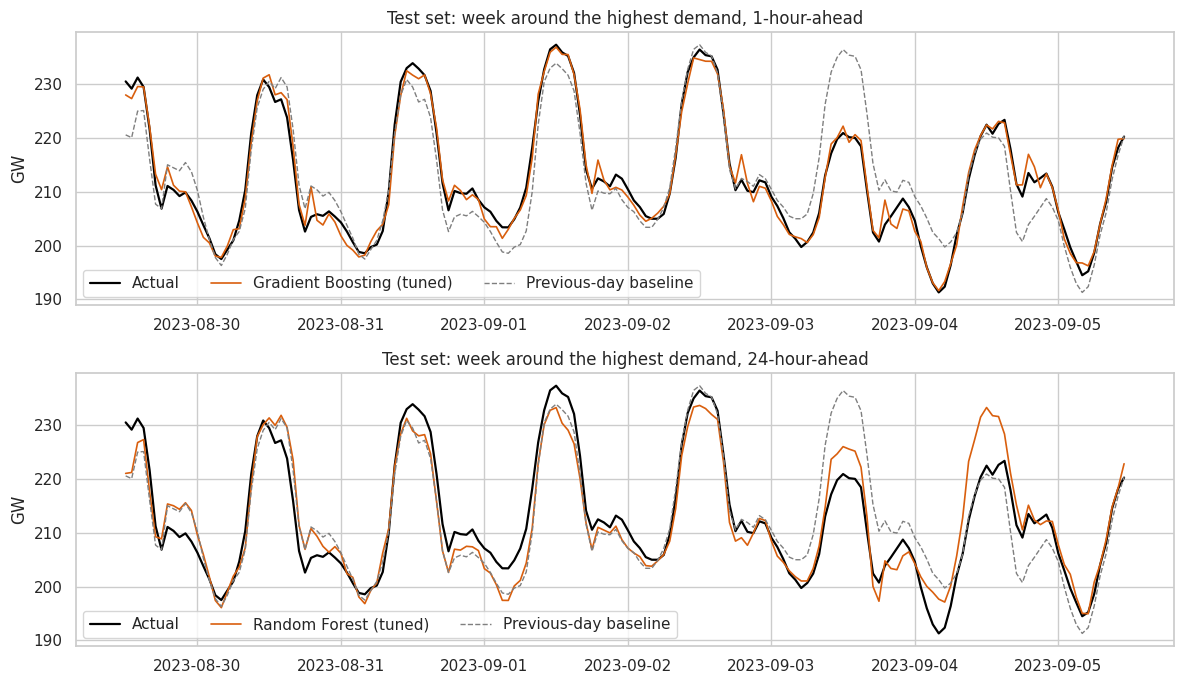

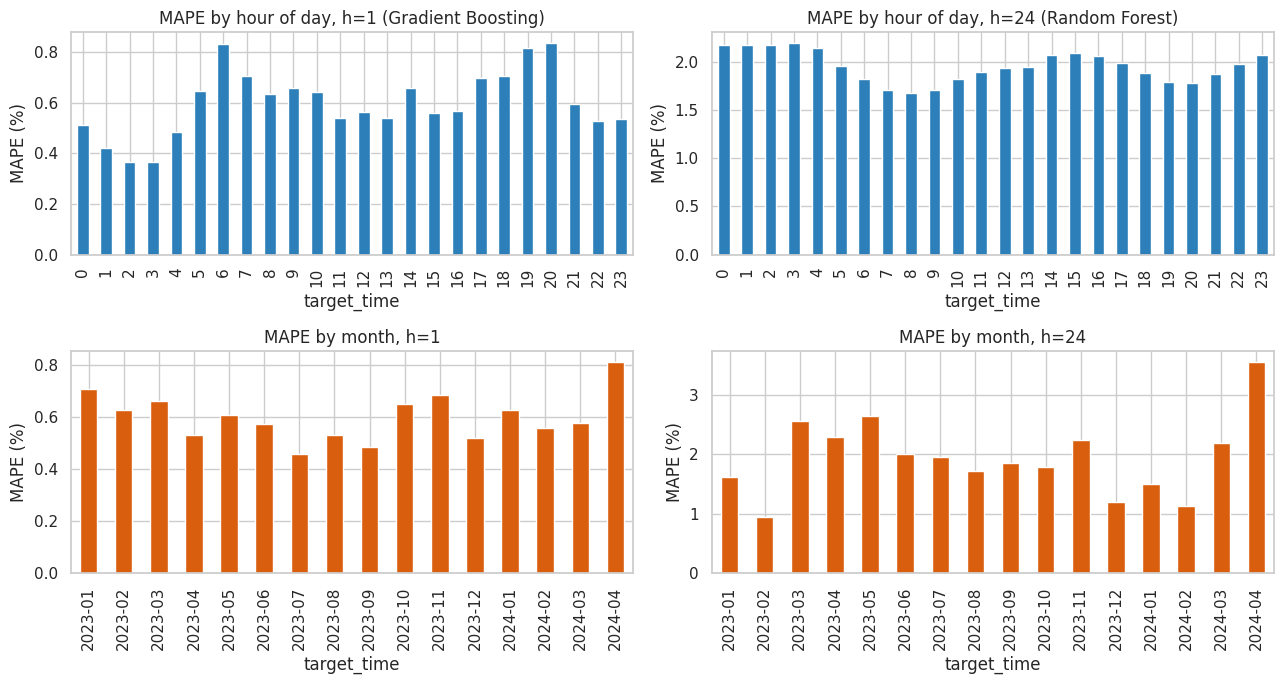

In [23]:

# Figure 1: Test-set week around the highest-demand observation.

fig, axes = plt.subplots(
    2,
    1,
    figsize=(12, 7)
)

for ax, h in zip(axes, (1, 24)):

    ds, te, pred, bm = finals[h]

    col = bm.lower().replace(" ", "_") + "_mw"

    tt = pd.to_datetime(pred["target_time"])

    peak = tt[pred["actual_mw"].idxmax()]

    w = (
        (tt >= peak - pd.Timedelta(days=3))
        &
        (tt < peak + pd.Timedelta(days=4))
    )

    ax.plot(
        tt[w],
        pred.loc[w, "actual_mw"] / 1000,
        color="black",
        lw=1.6,
        label="Actual"
    )

    ax.plot(
        tt[w],
        pred.loc[w, col] / 1000,
        color="#d95f0e",
        lw=1.2,
        label=f"{bm} (tuned)"
    )

    ax.plot(
        tt[w],
        pred.loc[w, "previous_day_mw"] / 1000,
        color="#7f7f7f",
        lw=1,
        ls="--",
        label="Previous-day baseline"
    )

    ax.set_title(
        f"Test set: week around the highest demand, {h}-hour-ahead"
    )

    ax.set_ylabel("GW")

    ax.legend(
        loc="lower left",
        ncol=3
    )

plt.tight_layout()

plt.savefig(
    "results/figures/06_test_peak_week.png",
    dpi=150
)

plt.show()


# Figure 2: Error by hour of day and month.

fig, axes = plt.subplots(
    2,
    2,
    figsize=(13, 7)
)

for j, h in enumerate((1, 24)):

    ds, te, pred, bm = finals[h]

    col = bm.lower().replace(" ", "_") + "_mw"

    tt = pd.to_datetime(pred["target_time"])

    ape = (
        (pred[col] - pred["actual_mw"]).abs()
        / pred["actual_mw"]
        * 100
    )

    # MAPE by hour.
    ape.groupby(
        tt.dt.hour
    ).mean().plot.bar(
        ax=axes[0, j],
        color="#2c7fb8"
    )

    axes[0, j].set_title(
        f"MAPE by hour of day, h={h} ({bm})"
    )

    axes[0, j].set_ylabel("MAPE (%)")

    # MAPE by month.
    ape.groupby(
        tt.dt.to_period("M")
    ).mean().plot.bar(
        ax=axes[1, j],
        color="#d95f0e"
    )

    axes[1, j].set_title(
        f"MAPE by month, h={h}"
    )

    axes[1, j].set_ylabel("MAPE (%)")


plt.tight_layout()

plt.savefig(
    "results/figures/06_error_by_hour_month.png",
    dpi=150
)

plt.show()


In [25]:
# Package generated results.
!zip -qr /content/day4_models_outputs.zip results

# Download to your computer.
from google.colab import files

files.download(
    "/content/day4_models_outputs.zip"
)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>